## Problema - Organización y búsqueda de productos en una tienda

**Equipo Extasys Code:** Juan Pablo León, Mateo Barrios, Santiago Lugo y Alejandro Peña

Una tienda tiene muchos productos registrados y recorrer toda una lista cada vez que necesita buscar uno resulta poco eficiente. Para resolverlo se implementa una Tabla Hash que usa como llave el código numérico de cada producto, con función hash h(código) = código % m y colisiones resueltas por encadenamiento.


In [ ]:
# @title Ingrese datos
equipo = "Extasys Code" # @param {"type":"string"}
nombre_estudiante = "Juan Pablo León, Mateo Barrios, Santiago Lugo y Alejandro Peña" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

El programa administra el inventario de una tienda. Cada producto tiene código, nombre, precio y cantidad disponible, y se guarda en una Tabla Hash de tamaño m que indica el usuario. La posición de cada producto se calcula con h(código) = código % m; por ejemplo, con m = 7 el código 101 queda en la posición 101 % 7 = 3.

Cuando dos productos dan la misma posición hay una colisión, y se resuelve por encadenamiento: cada posición de la tabla es una lista que puede guardar varios productos. Sobre la tabla se implementan cuatro operaciones: insertar (sin permitir códigos repetidos), buscar, eliminar y actualizar la cantidad. Todas calculan primero la posición con la función hash y solo recorren esa posición, nunca la tabla completa. Al final se muestra la tabla con todas sus posiciones para evidenciar las colisiones.


## 2) Requerimientos **[2 pts]**

### Requerimientos funcionales
1. Pedir el tamaño m de la tabla y crearla con m posiciones vacías.
2. Mostrar la tabla vacía con su índice y la palabra "Vacío".
3. Registrar n productos con código, nombre, precio y cantidad.
4. Calcular la posición de cada producto con h(código) = código % m.
5. Resolver las colisiones por encadenamiento, guardando varios productos en la misma posición.
6. Rechazar un producto si ya existe otro con el mismo código.
7. Buscar un producto por código y mostrar sus datos, o "El producto no está registrado".
8. Eliminar únicamente el producto indicado, o mostrar "No se encontró el producto".
9. Actualizar la cantidad disponible de un producto.
10. Mostrar la tabla completa con todos los productos de cada posición.

### Requerimientos no funcionales
1. La Tabla Hash se implementa a mano con una lista de listas; no se usa un diccionario de Python como tabla.
2. Buscar, eliminar y actualizar usan primero la función hash y recorren solo la posición correspondiente.
3. Buscar, insertar y eliminar cuestan O(1) en promedio.
4. Los mensajes en consola son claros y muestran la posición calculada y las colisiones.
5. El código está organizado en funciones pequeñas, una por operación.


## 3) Historias de usuario **[2 pts]**

Como encargado del inventario, quiero indicar el tamaño de la tabla hash, para crear la estructura donde se guardan los productos. Criterios de aceptación: Se pide m y se crean m posiciones. Se muestra cada índice con la palabra "Vacío".

Como encargado del inventario, quiero registrar n productos, para tenerlos organizados por su código. Criterios de aceptación: Cada producto se guarda en la posición código % m. Si dos productos dan la misma posición, los dos quedan encadenados en ella. Si el código ya existe, el producto no se registra y se avisa.

Como vendedor, quiero buscar un producto por su código, para consultar su precio y su cantidad sin recorrer todo el inventario. Criterios de aceptación: Solo se revisa la posición que da la función hash. Si existe, se muestran código, nombre, precio y cantidad. Si no, se muestra "El producto no está registrado".

Como encargado del inventario, quiero eliminar un producto por su código, para retirar lo que ya no se vende. Criterios de aceptación: Solo se quita ese producto y los demás de la misma posición se conservan. Si no existe, se muestra "No se encontró el producto".

Como encargado del inventario, quiero cambiar la cantidad disponible de un producto, para mantener el inventario al día. Criterios de aceptación: El producto se busca con la tabla hash. Se muestra la cantidad actual, se pide la nueva y se confirma con "Inventario actualizado correctamente".


## 4) Diagramas de flujo **[5 pts]**

### Diagrama de flujo general

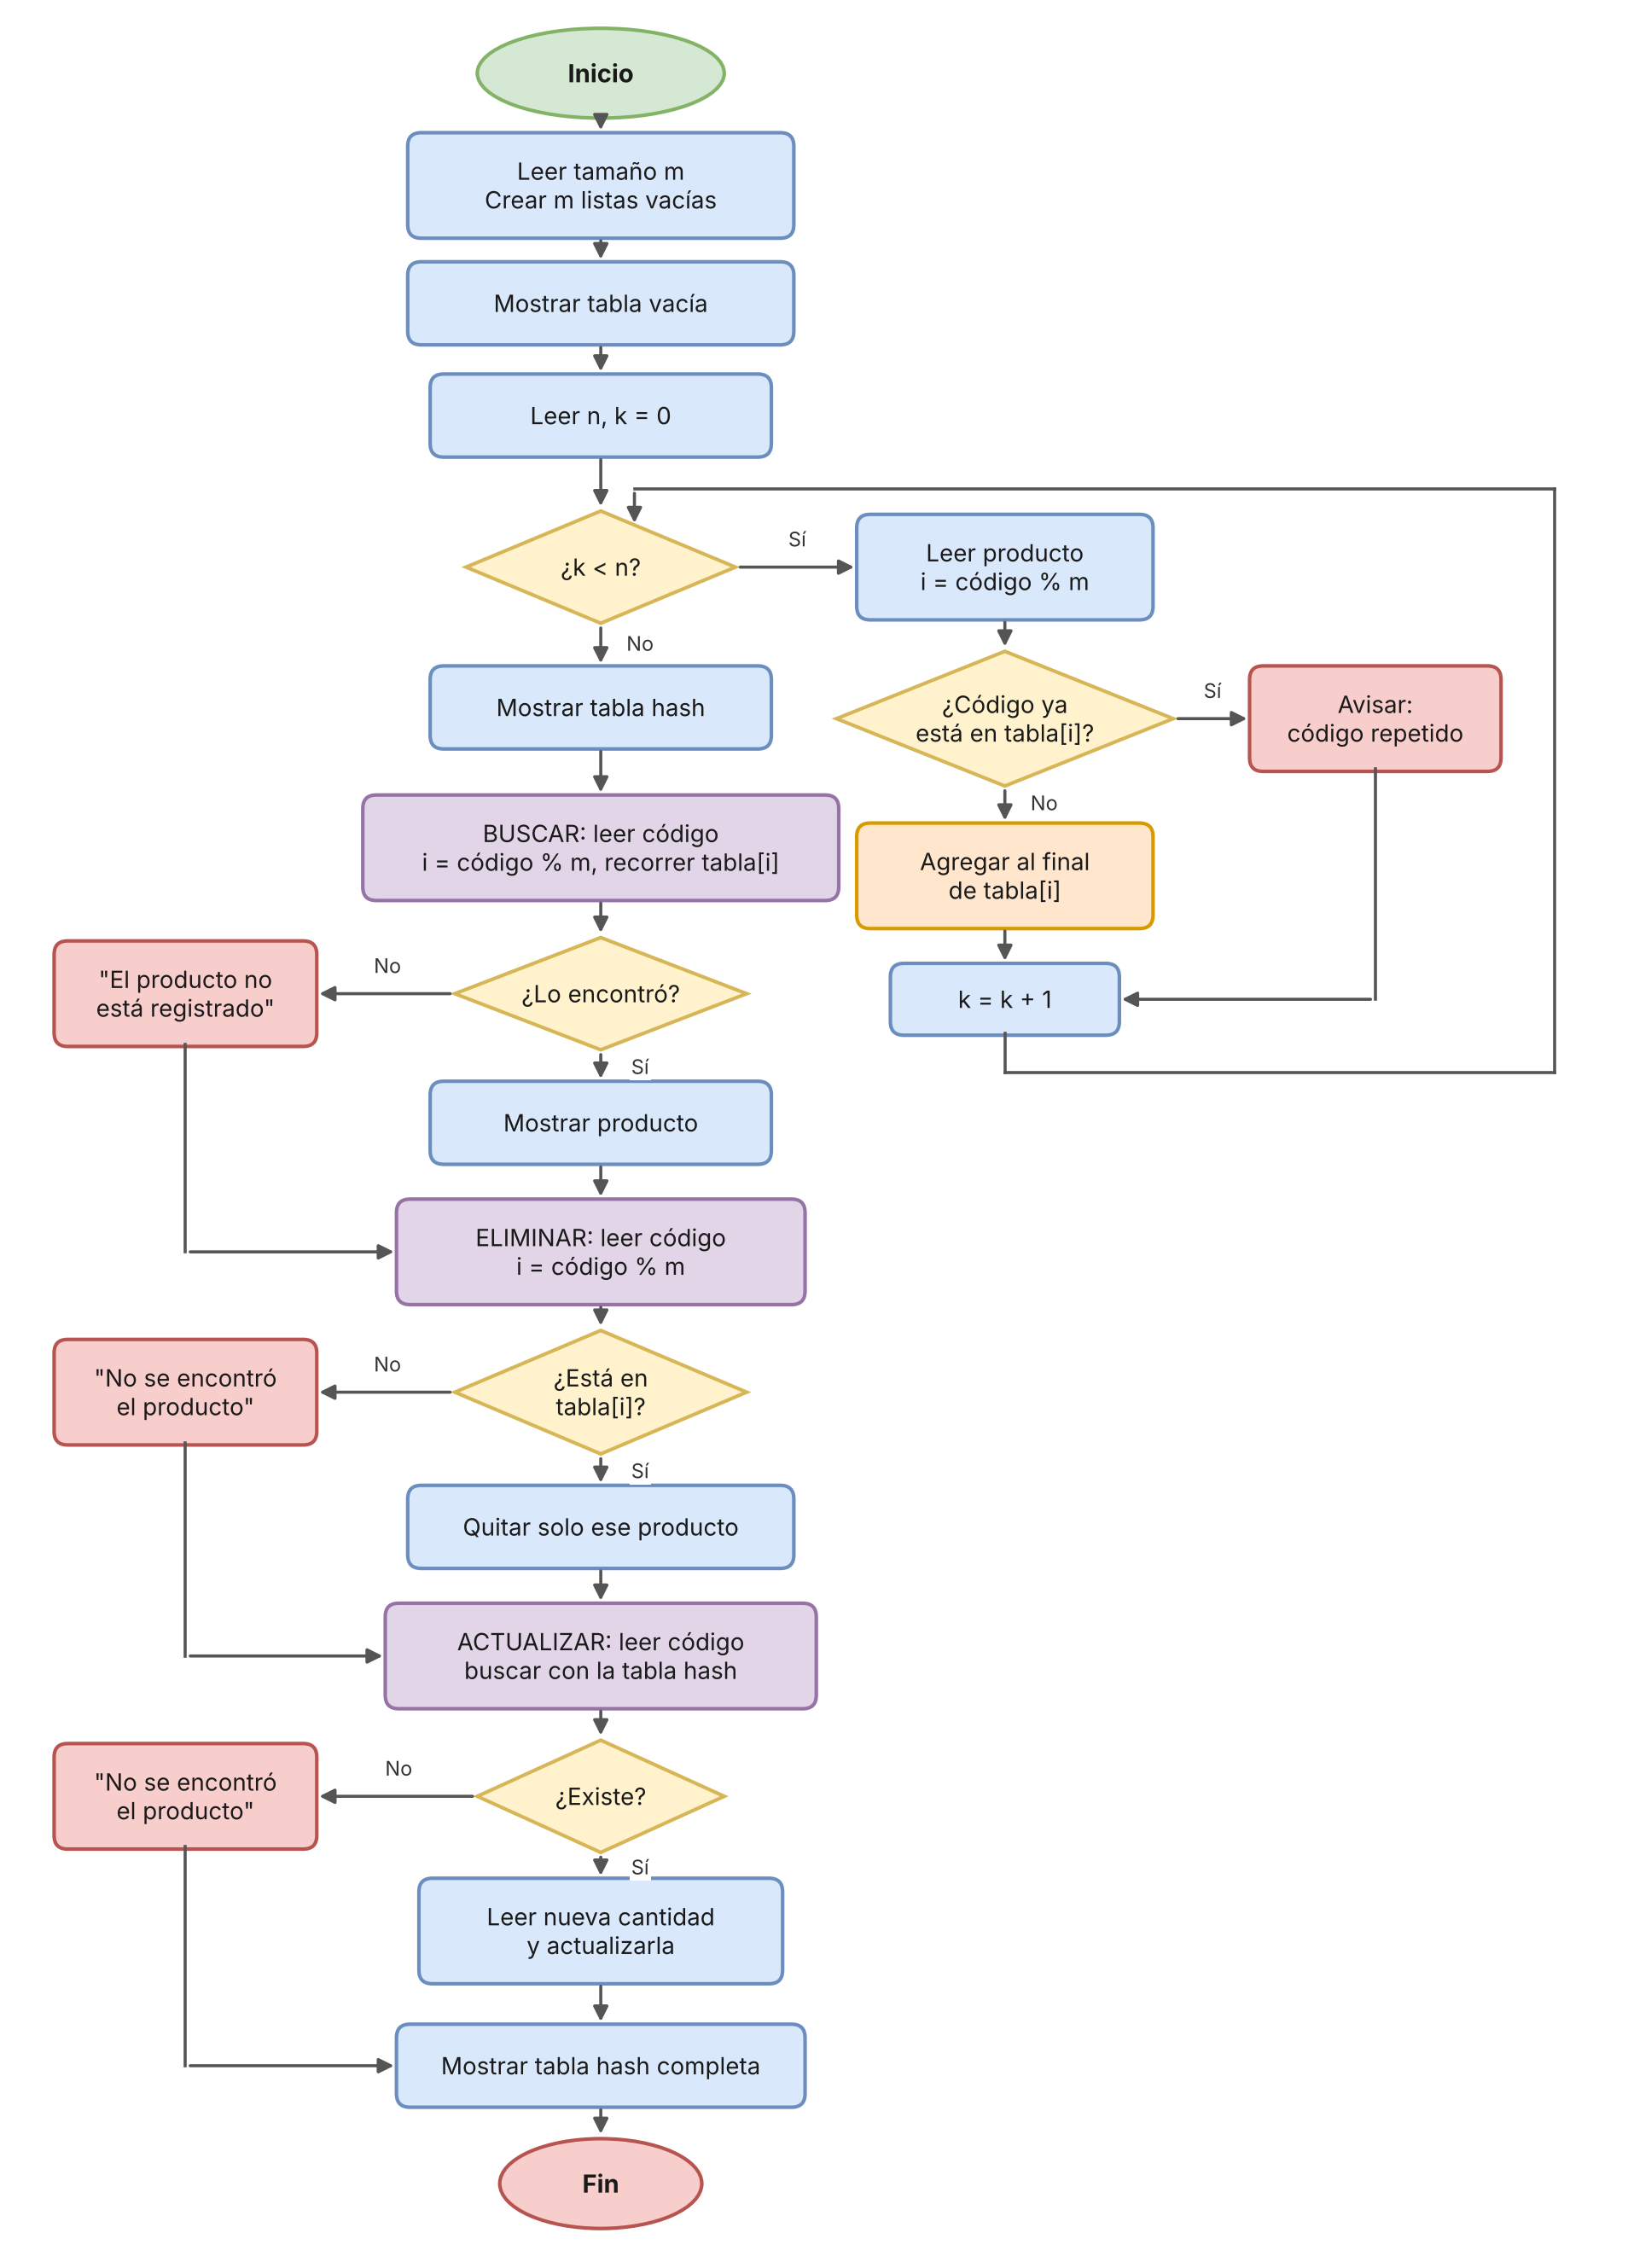

El diagrama muestra el proceso completo. Primero se lee m, se crean m listas vacías y se muestra la tabla vacía. Luego un ciclo registra los n productos: para cada uno se calcula i = código % m y se revisa si el código ya está en esa posición; si está, se avisa que es repetido, y si no, el producto se agrega al final de la lista de esa posición, que es el encadenamiento. Con la tabla llena se muestra su estado. Después vienen las tres consultas, que siempre empiezan calculando la posición con la función hash: buscar recorre solo esa posición y muestra el producto o avisa que no está, eliminar quita únicamente ese producto, y actualizar lo busca y cambia su cantidad. Al final se muestra la tabla hash completa.


### Diagrama de secuencia

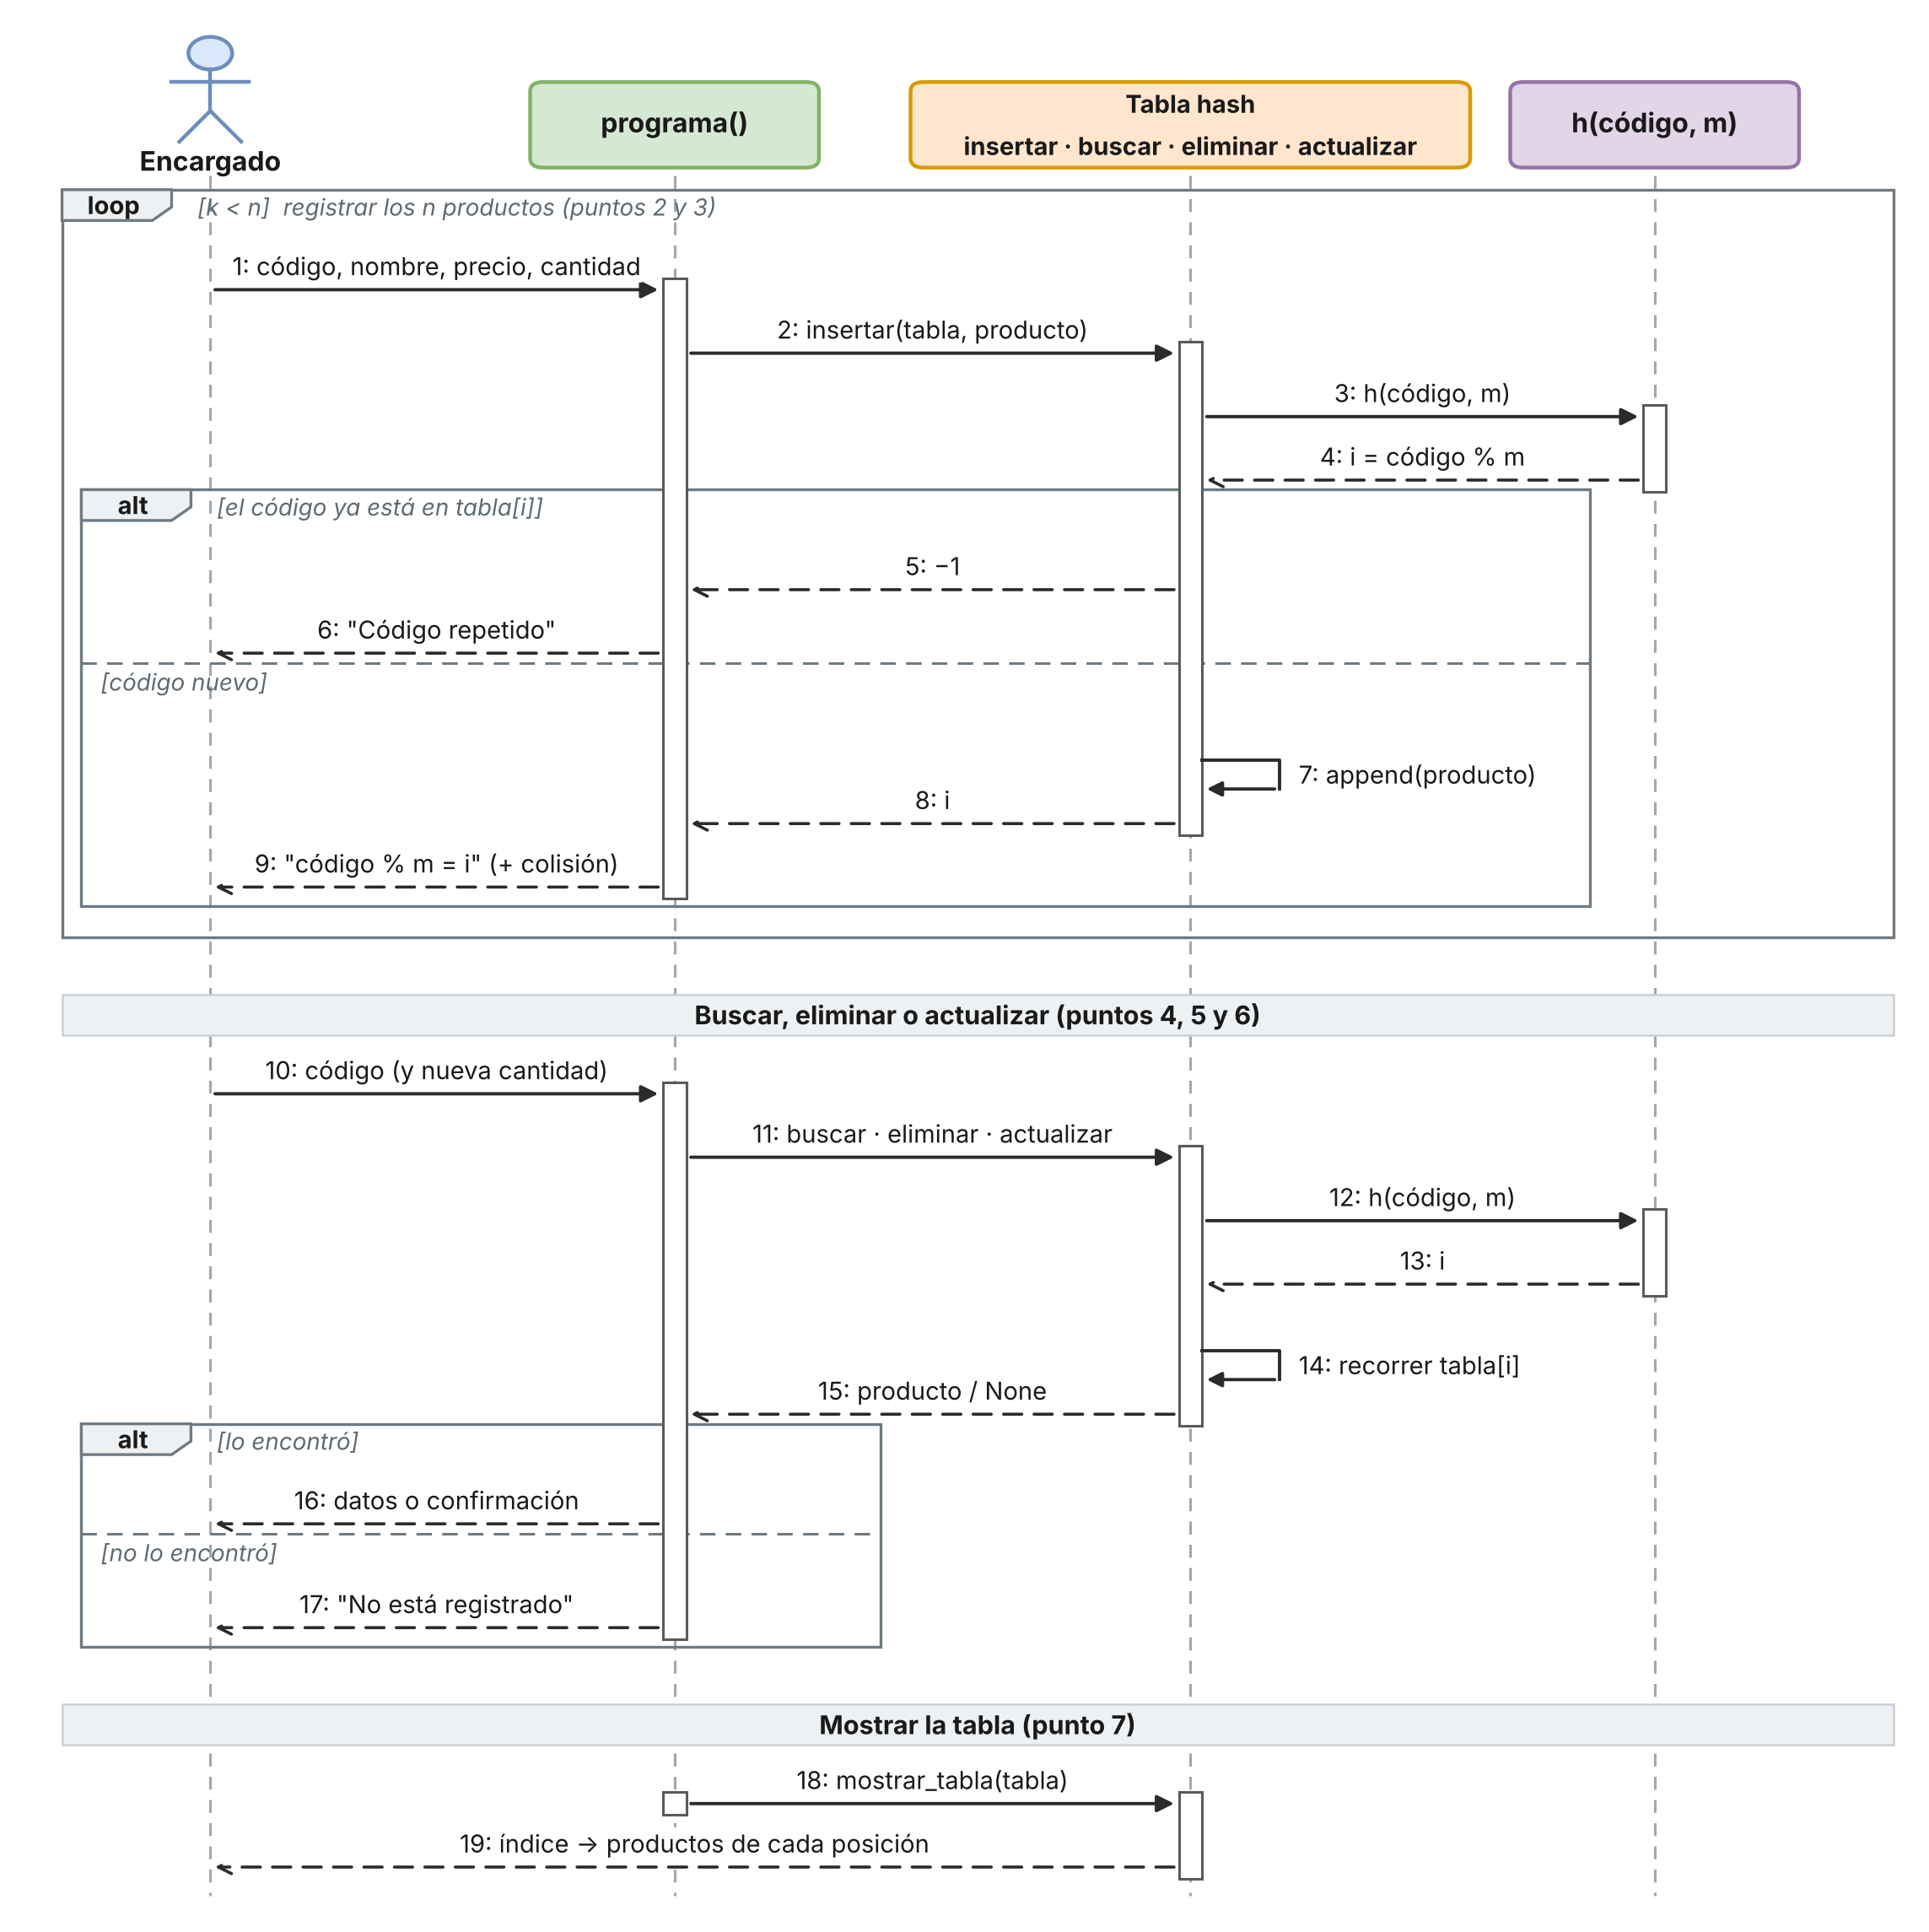
En el diagrama participan cuatro elementos: el **Encargado**, la función **programa()**, las operaciones de la **Tabla hash** y la función **h(código, m)**. En el registro, que se repite para cada uno de los n productos, el encargado entrega los datos, `insertar` le pide a `h` la posición i, revisa solo `tabla[i]` para descartar códigos repetidos y devuelve la posición (o −1). El programa muestra la cuenta de la función hash y avisa si hubo colisión.

Buscar, eliminar y actualizar siguen el mismo patrón: el programa llama la operación, esta calcula i con `h` y recorre únicamente la cadena de esa posición. El fragmento **alt** muestra las dos salidas: si el producto existe se muestran sus datos, el antes y después o la cantidad nueva; si no, se informa que no está registrado. Al final, `mostrar_tabla` imprime cada índice con los productos de su cadena.


### Diagrama de casos de uso

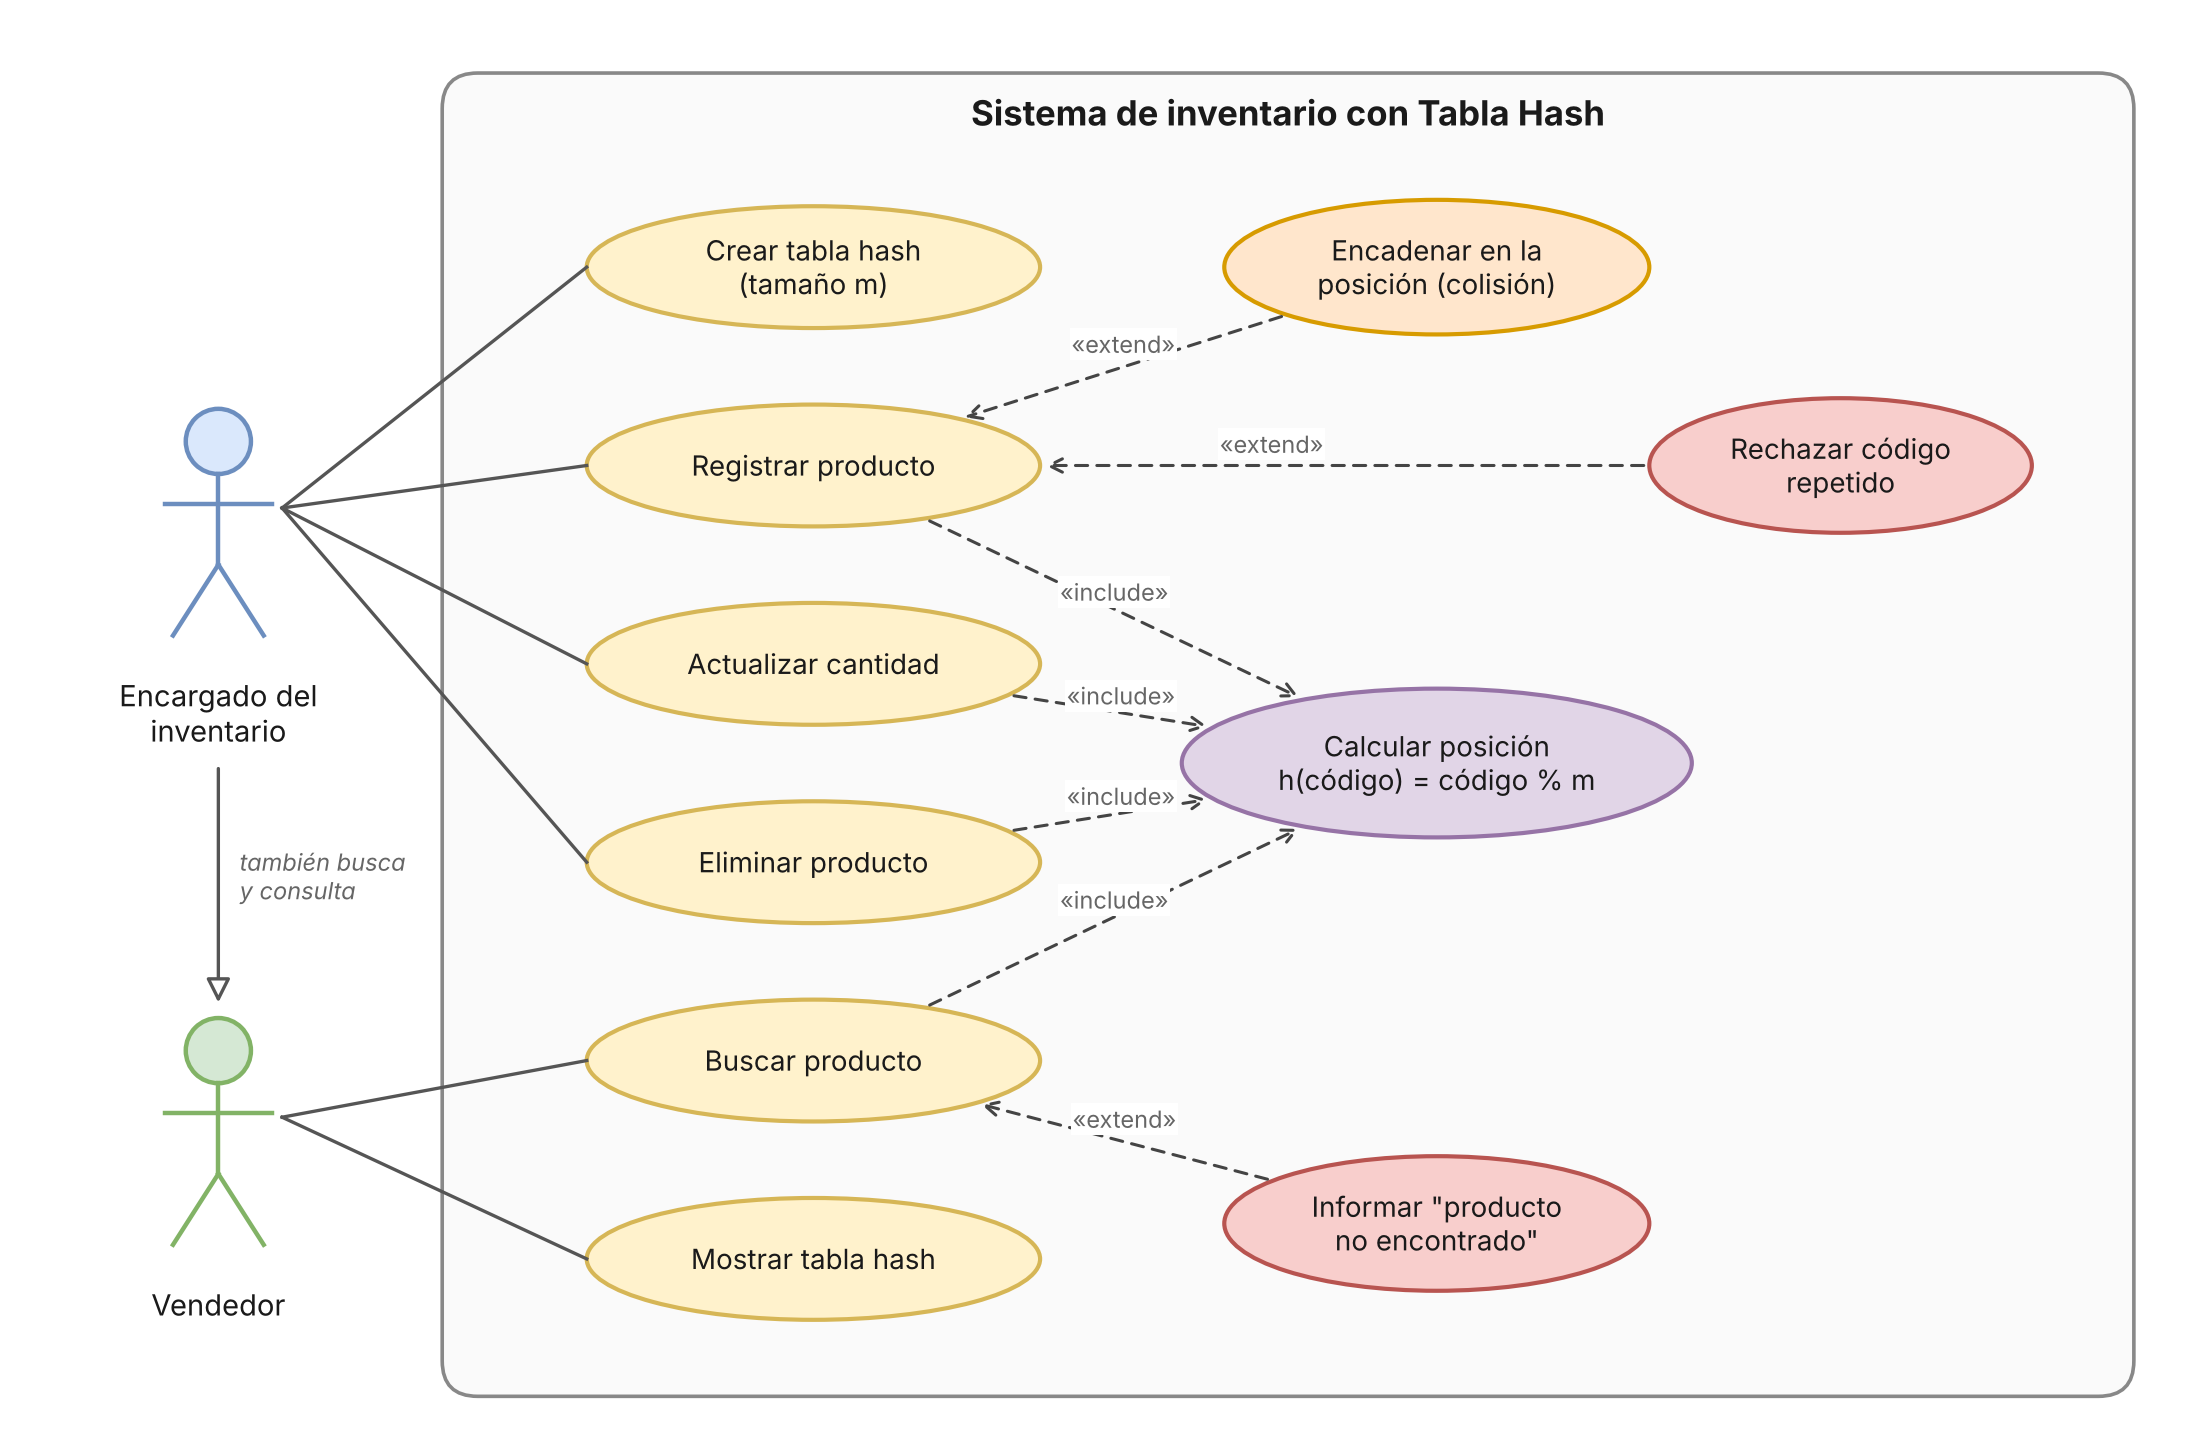

Hay dos actores. El **Encargado del inventario** crea la tabla, registra, actualiza y elimina productos; el **Vendedor** busca productos y consulta la tabla. La flecha de generalización indica que el encargado también puede hacer todo lo que hace el vendedor.

Registrar, actualizar, eliminar y buscar **incluyen** (`«include»`) el caso *Calcular posición h(código) = código % m*, porque todas empiezan por la función hash. Los casos alternativos se modelan con `«extend»`: al registrar puede haber una colisión, que se resuelve encadenando el producto en su posición, o un código repetido, que se rechaza; y al buscar puede pasar que el producto no exista, caso en el que se informa al usuario.


### 5) Análisis de complejidad **[15 pts]**

### Justificación

La tabla tiene m posiciones y guarda n productos. Si la función hash reparte bien los códigos, cada posición tiene en promedio α = n / m productos, que se llama factor de carga.

- **Función hash h(código) = código % m:** una sola operación: **O(1)**.
- **Insertar:** calcula la posición en O(1) y recorre la lista de esa posición para revisar que el código no esté repetido; luego agrega al final. Si la posición tiene k productos: T(n) = c₁ + c₂·k. En promedio k = α, así que cuesta **O(1 + α)**.
- **Buscar:** calcula la posición y recorre solo esa lista hasta encontrar el código: T(n) = c₁ + c₂·k, **O(1 + α)** en promedio.
- **Eliminar:** igual que buscar, y al encontrarlo lo quita de la lista: **O(1 + α)**.
- **Actualizar:** usa buscar y cambia la cantidad en O(1): **O(1 + α)**.
- **Mostrar la tabla:** recorre las m posiciones y los n productos: **O(m + n)**.

Cuando m es parecido a n, α es una constante y las operaciones quedan en **O(1)** en promedio.

### Función T[n]

Para buscar, eliminar o actualizar un código en una posición con k productos:

T(n) = c₁ + c₂·k

- **Mejor caso:** la posición está vacía o el producto es el primero de la cadena, k = 0 o 1: **T(n) = O(1)**.
- **Caso promedio:** k = n / m: **T(n) = O(1 + n/m)**.
- **Peor caso:** todos los códigos dan la misma posición (por ejemplo m = 1) y la tabla se vuelve una sola lista: k = n, **T(n) = O(n)**.

Registrar los n productos cuesta O(n) en promedio, y O(n²) en el peor caso, porque cada inserción revisa toda la cadena para evitar códigos repetidos.

| Operación | Mejor caso | Promedio | Peor caso |
|---|---|---|---|
| h(código) | O(1) | O(1) | O(1) |
| Insertar | O(1) | O(1 + α) | O(n) |
| Buscar | O(1) | O(1 + α) | O(n) |
| Eliminar | O(1) | O(1 + α) | O(n) |
| Actualizar | O(1) | O(1 + α) | O(n) |
| Mostrar tabla | O(m + n) | O(m + n) | O(m + n) |

La memoria es O(m + n): las m listas de la tabla y los n productos.


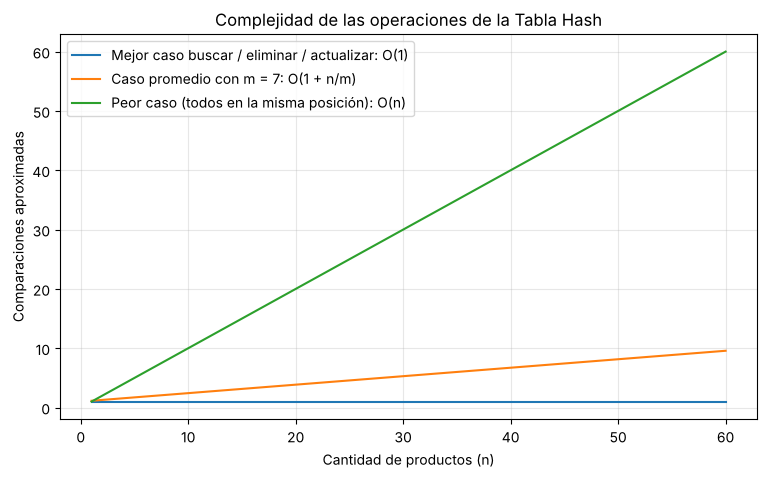

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(1, 61)
m = 7

plt.figure(figsize=(9, 5))
plt.plot(n, np.ones(len(n)), label="Mejor caso buscar / eliminar / actualizar: O(1)")
plt.plot(n, 1 + n / m, label="Caso promedio con m = 7: O(1 + n/m)")
plt.plot(n, n, label="Peor caso (todos en la misma posición): O(n)")
plt.xlabel("Cantidad de productos (n)")
plt.ylabel("Comparaciones aproximadas")
plt.title("Complejidad de las operaciones de la Tabla Hash")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 6) Código funcional **[15 pts]**

La tabla es una lista de m listas, una por posición. Cada producto se guarda como un diccionario con `codigo`, `nombre`, `precio` y `cantidad`, y se compara por su código. Las colisiones quedan en la misma lista de la posición, que es el encadenamiento.


In [1]:
def crear_tabla(m):
    return [[] for _ in range(m)]


def h(codigo, m):
    return codigo % m


def precio_texto(precio):
    return "$" + f"{precio:,}".replace(",", ".")


def insertar(tabla, producto):
    i = h(producto["codigo"], len(tabla))
    for p in tabla[i]:
        if p["codigo"] == producto["codigo"]:
            return -1
    tabla[i].append(producto)
    return i


def buscar(tabla, codigo):
    i = h(codigo, len(tabla))
    for p in tabla[i]:
        if p["codigo"] == codigo:
            return p
    return None


def eliminar(tabla, codigo):
    i = h(codigo, len(tabla))
    for k in range(len(tabla[i])):
        if tabla[i][k]["codigo"] == codigo:
            tabla[i].pop(k)
            return True
    return False


def actualizar(tabla, codigo, cantidad):
    p = buscar(tabla, codigo)
    if p is None:
        return False
    p["cantidad"] = cantidad
    return True


def mostrar_posicion(tabla, i):
    if len(tabla[i]) == 0:
        return "Vacío"
    return "   ".join(f"{p['codigo']} - {p['nombre']}" for p in tabla[i])


def mostrar_tabla(tabla):
    print("=" * 40)
    print("TABLA HASH".center(40))
    print("=" * 40)
    for i in range(len(tabla)):
        print(f"{i} -> {mostrar_posicion(tabla, i)}")


def pedir_producto():
    codigo = int(input("Código: "))
    nombre = input("Nombre: ")
    precio = int(input("Precio: "))
    cantidad = int(input("Cantidad: "))
    return {"codigo": codigo, "nombre": nombre, "precio": precio, "cantidad": cantidad}


def programa():
    print("PUNTO 1. CREAR LA TABLA HASH")
    m = int(input("Ingrese el tamaño de la tabla hash: "))
    tabla = crear_tabla(m)
    print("\nÍndice   Producto")
    for i in range(m):
        print(f"{i:<8} Vacío")

    print("\nPUNTO 2 Y 3. INSERTAR PRODUCTOS Y COLISIONES")
    n = int(input("¿Cuántos productos desea registrar?: "))
    for k in range(n):
        print(f"\nProducto {k + 1}")
        producto = pedir_producto()
        i = h(producto["codigo"], m)
        ocupada = len(tabla[i]) > 0
        if insertar(tabla, producto) == -1:
            print(f"Ya existe un producto con el código {producto['codigo']}, no se registra.")
        else:
            print(f"{producto['codigo']} % {m} = {i} -> se guarda en la posición {i}")
            if ocupada:
                print(f"Colisión en la posición {i}: se encadena con los productos que ya estaban.")
    print()
    mostrar_tabla(tabla)

    print("\nPUNTO 4. BUSCAR UN PRODUCTO")
    codigo = int(input("Ingrese el código del producto: "))
    print(f"Se busca solo en la posición {h(codigo, m)}")
    p = buscar(tabla, codigo)
    if p is None:
        print("El producto no está registrado.")
    else:
        print("Producto encontrado")
        print(f"Código: {p['codigo']}")
        print(f"Nombre: {p['nombre']}")
        print(f"Precio: {precio_texto(p['precio'])}")
        print(f"Cantidad disponible: {p['cantidad']}")

    print("\nPUNTO 5. ELIMINAR UN PRODUCTO")
    codigo = int(input("Código del producto que desea eliminar: "))
    i = h(codigo, m)
    print(f"Antes:   Índice {i}: {mostrar_posicion(tabla, i)}")
    if eliminar(tabla, codigo):
        print(f"Después: Índice {i}: {mostrar_posicion(tabla, i)}")
    else:
        print("No se encontró el producto.")

    print("\nPUNTO 6. ACTUALIZAR INVENTARIO")
    codigo = int(input("Código: "))
    p = buscar(tabla, codigo)
    if p is None:
        print("No se encontró el producto.")
    else:
        print(f"Producto: {p['nombre']}")
        print(f"Cantidad actual: {p['cantidad']}")
        nueva = int(input("Nueva cantidad: "))
        actualizar(tabla, codigo, nueva)
        print("Inventario actualizado correctamente.")
        print(f"{p['nombre']} - {p['cantidad']} unidades")

    print("\nPUNTO 7. MOSTRAR LA TABLA HASH")
    mostrar_tabla(tabla)


### Prueba final

Ejecución con una tabla de tamaño 7 y los productos del enunciado: 101 Arroz, 108 Huevos, 115 Azúcar, 312 Café, 209 Leche y 302 Galletas. Los códigos 101, 108 y 115 colisionan en la posición 3. Luego se busca el 108, se elimina el 108 y se actualiza el arroz a 35 unidades.


In [ ]:
programa()


PUNTO 1. CREAR LA TABLA HASH
Ingrese el tamaño de la tabla hash: 7

Índice   Producto
0        Vacío
1        Vacío
2        Vacío
3        Vacío
4        Vacío
5        Vacío
6        Vacío

PUNTO 2 Y 3. INSERTAR PRODUCTOS Y COLISIONES
¿Cuántos productos desea registrar?: 6

Producto 1
Código: 101
Nombre: Arroz
Precio: 4500
Cantidad: 20
101 % 7 = 3 -> se guarda en la posición 3

Producto 2
Código: 108
Nombre: Huevos
Precio: 16000
Cantidad: 12
108 % 7 = 3 -> se guarda en la posición 3
Colisión en la posición 3: se encadena con los productos que ya estaban.

Producto 3
Código: 115
Nombre: Azúcar
Precio: 3200
Cantidad: 18
115 % 7 = 3 -> se guarda en la posición 3
Colisión en la posición 3: se encadena con los productos que ya estaban.

Producto 4
Código: 312
Nombre: Café
Precio: 12000
Cantidad: 10
312 % 7 = 4 -> se guarda en la posición 4

Producto 5
Código: 209
Nombre: Leche
Precio: 3800
Cantidad: 15
209 % 7 = 6 -> se guarda en la posición 6

Producto 6
Código: 302
Nombre: Galletas
Prec

## 7) Tests aplicados **[15 pts]**

Se comprueba cada operación con los datos del enunciado y con casos borde: colisiones, código repetido, búsqueda y eliminación de códigos que no existen, tabla vacía y m = 1, donde todo colisiona. Al final se prueban 200 tablas aleatorias.


In [ ]:
def producto(codigo, nombre="Producto", precio=1000, cantidad=1):
    return {"codigo": codigo, "nombre": nombre, "precio": precio, "cantidad": cantidad}


def codigos(tabla, i):
    return [p["codigo"] for p in tabla[i]]


def test(nombre, obtenido, esperado):
    assert obtenido == esperado, f"{nombre}: se obtuvo {obtenido}, pero se esperaba {esperado}"
    print(f"Paso caso de prueba {nombre}: {obtenido}")


tabla = crear_tabla(7)
test("Tabla vacía de tamaño 7", tabla, [[], [], [], [], [], [], []])
test("h(101) con m = 7", h(101, 7), 3)
test("h(108) con m = 7", h(108, 7), 3)
test("h(312) con m = 7", h(312, 7), 4)

insertar(tabla, producto(101, "Arroz", 4500, 20))
insertar(tabla, producto(108, "Huevos", 16000, 12))
insertar(tabla, producto(115, "Azúcar", 3200, 18))
insertar(tabla, producto(312, "Café", 12000, 10))
insertar(tabla, producto(209, "Leche", 3800, 15))
insertar(tabla, producto(302, "Galletas", 2800, 25))
test("Colisión encadenada en la posición 3", codigos(tabla, 3), [101, 108, 115])
test("Café en la posición 4", codigos(tabla, 4), [312])
test("Galletas en la posición 1", codigos(tabla, 1), [302])
test("Código repetido no se inserta", insertar(tabla, producto(101, "Otro")), -1)
test("La posición 3 sigue igual", codigos(tabla, 3), [101, 108, 115])

test("Buscar 108", buscar(tabla, 108)["nombre"], "Huevos")
test("Buscar 115, último de la cadena", buscar(tabla, 115)["nombre"], "Azúcar")
test("Buscar código inexistente", buscar(tabla, 500), None)
test("Buscar código que cae en una posición ocupada", buscar(tabla, 122), None)

test("Eliminar 108", eliminar(tabla, 108), True)
test("Solo se quitó el 108", codigos(tabla, 3), [101, 115])
test("Eliminar código inexistente", eliminar(tabla, 108), False)

test("Actualizar cantidad del 101", actualizar(tabla, 101, 35), True)
test("Nueva cantidad del arroz", buscar(tabla, 101)["cantidad"], 35)
test("Actualizar código inexistente", actualizar(tabla, 999, 5), False)
test("Formato de precio", precio_texto(16000), "$16.000")

uno = crear_tabla(1)
for c in [5, 9, 14]:
    insertar(uno, producto(c))
test("Con m = 1 todo colisiona en la posición 0", codigos(uno, 0), [5, 9, 14])
test("Buscar en tabla vacía", buscar(crear_tabla(5), 10), None)
test("Eliminar en tabla vacía", eliminar(crear_tabla(5), 10), False)

import random
random.seed(11)
for prueba in range(200):
    m = random.randint(1, 20)
    t = crear_tabla(m)
    usados = random.sample(range(1, 1000), random.randint(0, 40))
    for c in usados:
        insertar(t, producto(c))
    for c in usados:
        assert buscar(t, c)["codigo"] == c
        assert c in codigos(t, c % m)
    assert sum(len(p) for p in t) == len(usados)
    for c in usados[: len(usados) // 2]:
        assert eliminar(t, c)
        assert buscar(t, c) is None
print("Paso caso de prueba 200 tablas aleatorias: inserción, búsqueda y eliminación correctas")


Paso caso de prueba Tabla vacía de tamaño 7: [[], [], [], [], [], [], []]
Paso caso de prueba h(101) con m = 7: 3
Paso caso de prueba h(108) con m = 7: 3
Paso caso de prueba h(312) con m = 7: 4
Paso caso de prueba Colisión encadenada en la posición 3: [101, 108, 115]
Paso caso de prueba Café en la posición 4: [312]
Paso caso de prueba Galletas en la posición 1: [302]
Paso caso de prueba Código repetido no se inserta: -1
Paso caso de prueba La posición 3 sigue igual: [101, 108, 115]
Paso caso de prueba Buscar 108: Huevos
Paso caso de prueba Buscar 115, último de la cadena: Azúcar
Paso caso de prueba Buscar código inexistente: None
Paso caso de prueba Buscar código que cae en una posición ocupada: None
Paso caso de prueba Eliminar 108: True
Paso caso de prueba Solo se quitó el 108: [101, 115]
Paso caso de prueba Eliminar código inexistente: False
Paso caso de prueba Actualizar cantidad del 101: True
Paso caso de prueba Nueva cantidad del arroz: 35
Paso caso de prueba Actualizar código in

### Pruebas de desempeño

Se mide el tiempo promedio de 300 búsquedas (el mejor de 5 repeticiones, para reducir el ruido) para tablas de 500 a 8000 productos en dos situaciones: con m = n, donde los códigos se reparten en toda la tabla, y con m = 1, donde todos caen en la misma posición y forman una sola cadena.


     n   m = n (µs)   m = 1 (µs)
   500         0.18        10.12
  1000         0.20        19.77
  2000         0.19        35.80
  4000         0.19        72.18
  8000         0.19       144.52


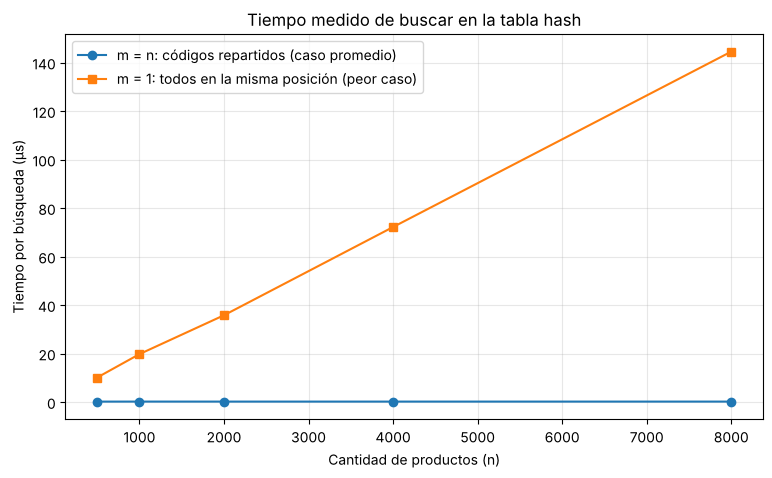

In [ ]:
import time
import random
import matplotlib.pyplot as plt


def tiempo_busqueda(n, m):
    tabla = crear_tabla(m)
    codigos = random.sample(range(1, 20 * n), n)
    for c in codigos:
        insertar(tabla, {"codigo": c, "nombre": "Producto", "precio": 1000, "cantidad": 1})
    consultas = random.sample(codigos, 300)
    mejor = None
    for repeticion in range(5):
        inicio = time.perf_counter()
        for c in consultas:
            buscar(tabla, c)
        t = (time.perf_counter() - inicio) / len(consultas) * 1e6
        if mejor is None or t < mejor:
            mejor = t
    return mejor


random.seed(5)
tamanos = [500, 1000, 2000, 4000, 8000]
promedio = [tiempo_busqueda(n, n) for n in tamanos]
peor = [tiempo_busqueda(n, 1) for n in tamanos]

print(f"{'n':>6} {'m = n (µs)':>12} {'m = 1 (µs)':>12}")
for n, a, b in zip(tamanos, promedio, peor):
    print(f"{n:>6} {a:>12.2f} {b:>12.2f}")

plt.figure(figsize=(9, 5))
plt.plot(tamanos, promedio, "o-", label="m = n: códigos repartidos (caso promedio)")
plt.plot(tamanos, peor, "s-", label="m = 1: todos en la misma posición (peor caso)")
plt.xlabel("Cantidad de productos (n)")
plt.ylabel("Tiempo por búsqueda (µs)")
plt.title("Tiempo medido de buscar en la tabla hash")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Interpretación

Con m = n los códigos quedan repartidos y cada cadena tiene en promedio un producto: buscar tardó entre 0.18 y 0.20 µs para todos los tamaños, es decir, el tiempo casi no cambia aunque n se multiplique por 16. Es el comportamiento O(1 + α) del caso promedio, con α = 1.

Con m = 1 todos los productos caen en la misma posición y la tabla se vuelve una sola lista: el tiempo pasó de 10.12 µs con n = 500 a 144.52 µs con n = 8000, es decir, se multiplicó por 14 cuando n se multiplicó por 16: crece en proporción a n. Es el peor caso O(n). La prueba confirma el análisis de complejidad: la tabla hash es rápida mientras la función hash reparta bien las llaves y m crezca con n.


## Conclusiones

1. La Tabla Hash resuelve el problema de la tienda: la función h(código) = código % m indica directamente en qué posición está cada producto, así que buscar, insertar, eliminar y actualizar no recorren todo el inventario.
2. El encadenamiento resuelve las colisiones sin perder productos: los códigos que dan la misma posición quedan en la misma lista, como 101, 108 y 115 en la posición 3 de la prueba final.
3. Las operaciones cuestan O(1 + α) en promedio y O(n) en el peor caso. Las pruebas de desempeño lo confirman: con m = n el tiempo de búsqueda se mantiene constante y con m = 1 crece linealmente.
4. El tamaño m de la tabla importa: si es mucho menor que la cantidad de productos, las cadenas se alargan y se pierde la ventaja de la tabla hash.
